# 029 — CatBoost com categorias nativas

CatBoost multiclasse CPU, uma thread, sem one-hot e sem pesos de classe. Pesquisa: depth ∈ {4,6}, learning_rate ∈ {0,03;0,1}, até 1000 iterações, early stopping=50. Candidato e iteração escolhidos apenas pela Macro F1 interna (sem ponderação das observações). Boosting Plain e limite indicativo de RAM para CTRs de 512 MB; este limite é uma indicação ao CatBoost, não uma garantia de consumo máximo.

Mesmas divisões estratificadas do 028; nenhuma aprendizagem conjunta de treino/teste. A validação fixa é comparação de desenvolvimento. Referências históricas: XGBoost 007=0,4491 e ensemble 025=0,4615/Kaggle 0,48. Reavaliamos um controlo XGBoost reconstruído e consultamos também o controlo do 028. Sem afirmar reprodução exata dos controlos originais.


**Ajuste de recursos:** a primeira tentativa foi terminada por falta de memória, antes de obter resultados. Fixaram-se `max_ctr_complexity=1`, `ctr_leaf_count_limit=256`, `border_count=32`, `one_hot_max_size=10` e `counter_calc_method="SkipTest"` em todos os candidatos e refits. O CatBoost pode usar one-hot internamente em categorias pequenas; não existe codificação externa. São restrições explícitas da experiência, podem afetar a qualidade e não são uma afinação pela validação fixa. O limite de RAM afeta CTRs e não limita toda a memória do processo. Fontes: [CTRs](https://catboost.ai/docs/en/references/training-parameters/ctr) e [desempenho](https://catboost.ai/docs/en/references/training-parameters/performance).

Para manter a pesquisa viável, fixaram-se também `rsm=0,2` (subamostragem de variáveis por nível) e `leaf_estimation_iterations=1` em todos os candidatos/refits, antes da seleção. A tentativa com todas as variáveis por nível foi interrompida por custo de treino, sem concluir candidato ou selecionar configuração. Não se confunde esta configuração restrita com CatBoost por defeito. [Orientações oficiais de desempenho](https://catboost.ai/docs/en/concepts/speed-up-training).


In [1]:
from pathlib import Path
import sys, json
from IPython.display import display, Image, Markdown
import pandas as pd

root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'src' / 'experiments_028_029.py').is_file() and (p / 'src' / 'preparar_dados.py').is_file()), None)
if root is None:
    raise FileNotFoundError('Coloca os dois módulos fornecidos em src/ e este notebook em notebooks/. Mantém src/preparar_dados.py do projeto.')
sys.path.insert(0, str(root))
from src.experiments_028_029 import run_experiment, load_data, write_final_report
print('Projeto:', root)
print('Python:', sys.version.split()[0])


Projeto: /workspace/scratch/4c152c3aae12
Python: 3.12.14


## Preparação e garantias

O módulo central `src/preparar_dados.py` faz a preparação fixa. No 028, o seu `DataPreprocessor` é ajustado por partição; os novos agregados recebem um ramo numérico adicional (mediana e normalização no MLP), sem modificar o comportamento de notebooks anteriores. No 029, números ausentes são tratados nativamente pelo CatBoost; categorias ausentes recebem um rótulo explícito. O esquema é consistente e códigos categóricos não são convertidos para quantidades por terem algarismos.

`AGE_RANGE`, `PID`, `HHID`, `PROXY` e `COUNTRY` ficam fora das entradas. BM1/BM2 e BMI/IMC são numéricos; cm/kg continuam uma suposição por confirmar. Os índices e a ordem são preservados. Não se eliminam linhas.

Os runners guardam resultados e o CatBoost guarda checkpoints por candidato. Para reutilizar resultados existentes, a célula seguinte verifica os hashes dos CSVs e da preparação. Define `REEXECUTAR=True` para executar novamente. Em caso de código/configuração alterados, reexecuta deliberadamente e apaga apenas os checkpoints correspondentes antes de retomar.


In [2]:
REEXECUTAR = False
path = root / 'reports' / '029_resultado.json'
_, _, _, _, metadata = load_data()
if path.exists() and not REEXECUTAR:
    result = json.loads(path.read_text())
    if any(result['metadata'][k] != metadata[k] for k in ['train_sha256','test_sha256','preparation_sha256']):
        raise ValueError('Os dados ou a preparação mudaram. Reexecuta a experiência; não uses métricas antigas.')
    print('Resultados executados anteriormente, dados/preparação conferidos.')
else:
    result = run_experiment('029')


Resultados executados anteriormente, dados/preparação conferidos.


## Resultados e curvas

Selecionado internamente: {'depth': 4, 'learning_rate': 0.1, 'iterations': 262, 'internal_macro_f1': 0.47177907723475787, 'seconds': 116.18257956299999}


,depth,learning_rate,iterations,internal_macro_f1,seconds
0,4,0.03,529,0.455020,210.993458
1,4,0.10,262,0.471779,116.182580
2,6,0.03,629,0.469605,324.611655
3,6,0.10,187,0.453782,114.762146


,modelo,parcela,macro_f1,accuracy
0,CatBoost,train,0.573321,0.578287
1,CatBoost,validation,0.448318,0.462380
2,XGBoost reconstruído,train,0.960867,0.952332
3,XGBoost reconstruído,validation,0.446205,0.450524


,classe,escalão,F1,recall,precision,support
0,0,15–17,0.800000,0.878049,0.734694,41.000000
1,1,18–19,0.346154,0.264706,0.500000,34.000000
2,2,20–24,0.544379,0.575000,0.516854,80.000000
3,3,25–29,0.302158,0.280000,0.328125,75.000000
4,4,30–34,0.240602,0.177778,0.372093,90.000000
5,5,35–39,0.375000,0.395349,0.356643,129.000000
6,6,40–44,0.418605,0.470930,0.376744,172.000000
7,7,45–49,0.344156,0.306358,0.392593,173.000000
8,8,50–54,0.620000,0.685083,0.566210,181.000000
9,9,55–59,0.609572,0.596059,0.623711,203.000000


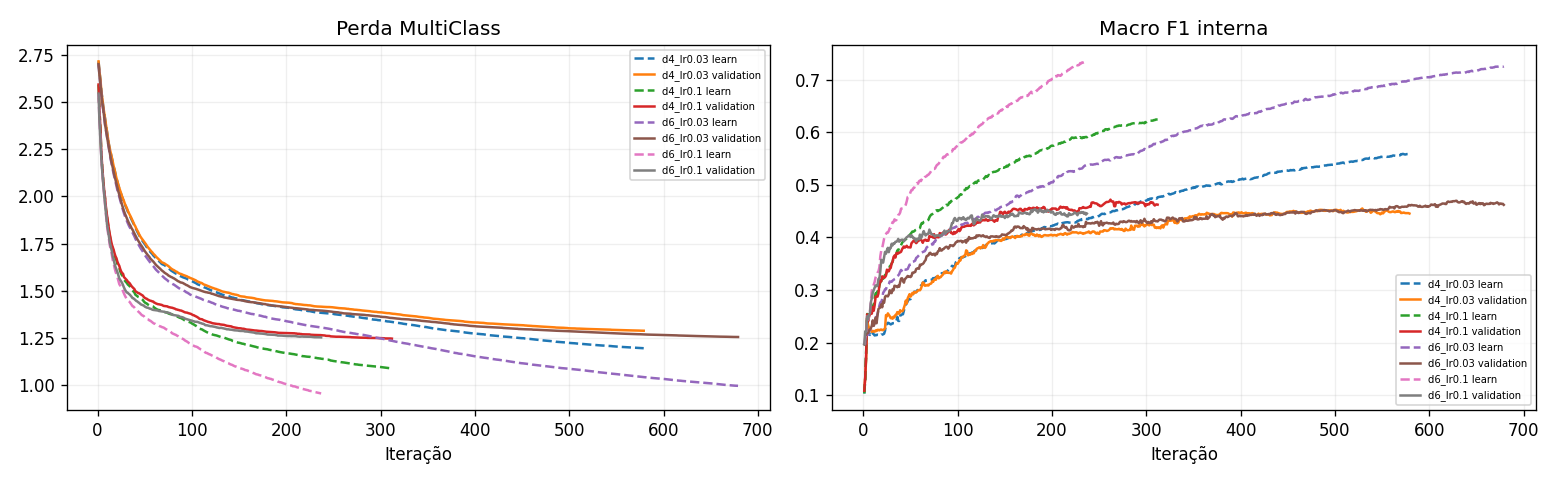

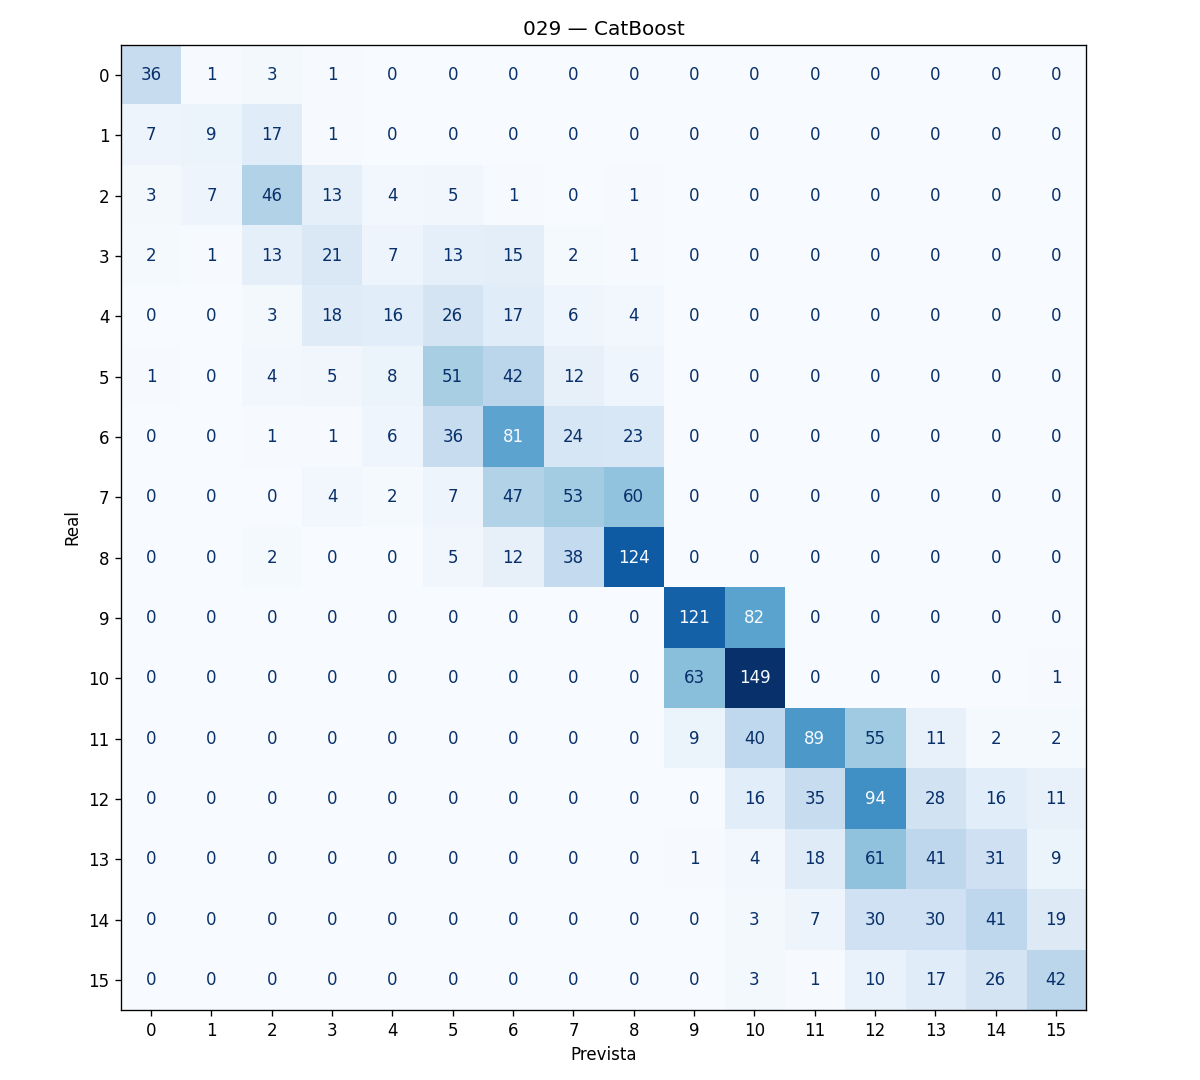

In [3]:
display(pd.DataFrame(result['candidates']))
print('Selecionado internamente:',result['selected'])
display(pd.DataFrame([{'modelo':model,'parcela':split,**{k:m[k] for k in ['macro_f1','accuracy']}} for model,splits in [('CatBoost',result['metrics']),('XGBoost reconstruído',result['xgboost_control'])] for split,m in splits.items()]))
display(pd.DataFrame(result['metrics']['validation']['per_class']).style.apply(lambda row:['font-weight:bold' if row['classe'] in [1,6,13] else '' for _ in row],axis=1))
display(Image(filename=str(root/'reports/029_curvas.png')))
display(Image(filename=str(root/'reports/029_confusion.png')))


## Submissão e verificações

Treino completo com configuração escolhida internamente. CSV relido e validado: 3.655 linhas, `RowId,AGE_RANGE`, RowIds copiados do exemplo oficial, classes inteiras 0–15 e sem índice. Duplicados são detetados entre os ficheiros anteriores disponíveis; a ausência de CSVs 016/019/025 impede comparar com esses ficheiros específicos aqui. Não foi submetido nada ao Kaggle.

In [5]:
print(json.dumps(result['submission'],ensure_ascii=False,indent=2))
print(write_final_report())

{
  "path": "submissions/submission_029_catboost.csv",
  "duplicates": [],
  "differences": {
    "submission_028_ensemble_features_dominio.csv": 1195,
    "submission_013_mlp_arquitetura.csv": 1678,
    "submission_014_xgboost_mlp.csv": 1214,
    "submission_001_regressao_logistica(1).csv": 1722,
    "submission_012_mlp_perda_ponderada.csv": 1678,
    "submission_004_arvore_decisao.csv": 2144,
    "submission_015_mlp_learning_rate.csv": 1556,
    "submission_002_regressao_logistica_regularizada.csv": 1484
  }
}
/workspace/scratch/4c152c3aae12/reports/experiments_028_029.md


## Conclusão e Decisão 
- Data: 13/11
- Pontuação Kaggle: 0.46
- Melhorias: testar ponderação suave das classes e, depois, uma mistura das probabilidades do CatBoost com o ensemble 025, escolhendo os pesos na validação interna.